# Demand Tier Relabelling

Assigns **LOW / MEDIUM / HIGH** demand tiers to each (date, shift) based on domain-expert scoring rules.

- **Morning**: occupancy-driven (hotel guests eat breakfast)
- **Afternoon**: multi-feature scoring (occupancy + day-of-week + season + temperature + special day)
- **Hard overrides**: Christmas Eve, NYE, New Year's → always HIGH
- **Manager excluded** from headcount targets (admin role, not on the floor)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)


staff = pd.read_csv("../data_prep/outputs/rota_staffing_counts.csv", parse_dates=["date"])
occupancy   = pd.read_csv("../data_prep/outputs/occupancy_enriched.csv", parse_dates=["date"])

occ_col = [col for col in occupancy.columns if "occup" in col.lower()][0]
occupancy  = occupancy .rename(columns={occ_col: "occupancy_pct"})

# Exclude manager
staff = staff[staff["role"] != "manager"].copy()

daily_shift = staff.groupby(["date", "shift"]).agg(total_headcount=("headcount", "sum")).reset_index()
df = daily_shift.merge(occupancy , on="date", how="inner")
print(f"{len(df):,} rows  |  {df['date'].nunique()} unique dates  |  Manager excluded")

1,676 rows  |  840 unique dates  |  Manager excluded


## 1. Morning Tier — Occupancy Thresholds

Morning shifts are straightforward mostly because the highest traffic comes from the guests staying in the hotel. 
Breakfast is straightforwardly occupancy-driven:
- ≤ 35% → LOW
- 36–65% → MEDIUM
- \> 65% → HIGH

Hard override: Christmas Eve, NYE, New Year's Day → HIGH. 
Traditionally, especially in Europe, City hotels get their highest traffic around these days.

In [2]:
HARD_OVERRIDE_HIGH = {"christmas_eve", "christmas_day", "new_years_eve", "new_years_day"}

def morning_tier(row):
    if row["special_day_name"] in HARD_OVERRIDE_HIGH:
        return "high"
    occ = row["occupancy_pct"]
    if occ <= 35:
        return "low"
    elif occ <= 65:
        return "medium"
    else:
        return "high"

morning = df[df["shift"] == "morning"].copy()
morning["tier"] = morning.apply(morning_tier, axis=1)

print("Morning tier distribution:")
print(morning["tier"].value_counts().sort_index())
print(f"\n% breakdown: {morning['tier'].value_counts(normalize=True).sort_index().round(3).to_dict()}")

Morning tier distribution:
tier
high      332
low       163
medium    341
Name: count, dtype: int64

% breakdown: {'high': 0.397, 'low': 0.195, 'medium': 0.408}


## 2. Afternoon Tier — Domain-Expert Scoring

Each feature contributes a score (0–3). The sum maps to a tier.

| Feature | Levels | Scores |
|---|---|---|
| Occupancy | ≤35 / 36-65 / >65 | 0 / 2 / 3 |
| Day of week | Mon,Tue,Wed,Sun / Thu / Fri,Sat | 1 / 2 / 3 |
| Season | Winter / Spring,Autumn / Summer | 0 / 2 / 3 |
| Temperature | <5 / 5-15 / 15-25 / >25 | 0 / 1 / 3 / 3 |
| Special day | No / Yes | 0 / 3 |

Hard overrides: Christmas Eve, NYE, New Year's → always HIGH.

In [3]:
DAY_SCORES = {
    "Monday": 1, "Tuesday": 1, "Wednesday": 1,
    "Thursday": 2, "Friday": 3, "Saturday": 3, "Sunday": 1,
}
SEASON_SCORES = {"Winter": 0, "Spring": 1, "Summer": 4, "Autumn": 0}

def afternoon_score(row):
    occupancy = row["occupancy_pct"]
    occupancy_score = 0 if occupancy  <= 35 else (2 if occupancy  <= 65 else 3)

    day_score = DAY_SCORES.get(row["day_name"], 1)
    season_score = SEASON_SCORES.get(row["season"], 1)

    temp = row["temp_mean"]
    if temp < 5:
        temp_score = 0
    elif temp < 15:
        temp_score = 1
    elif temp <= 25:
        temp_score = 3
    else:
        temp_score = 3

    special_score = 3 if row["is_special_day"] == 1 else 0

    return occupancy_score + day_score + season_score + temp_score + special_score


def afternoon_tier(row):
    # Hard overrides
    if row["special_day_name"] in HARD_OVERRIDE_HIGH:
        return "high"
    score = afternoon_score(row)
    if score <= 4:
        return "low"
    elif score <= 6:
        return "medium"
    else:
        return "high"


afternoon = df[df["shift"] == "afternoon"].copy()
afternoon["score"] = afternoon.apply(afternoon_score, axis=1)
afternoon["tier"] = afternoon.apply(afternoon_tier, axis=1)

print("Afternoon tier distribution:")
print(afternoon["tier"].value_counts().sort_index())
print(f"\n% breakdown: {afternoon['tier'].value_counts(normalize=True).sort_index().round(3).to_dict()}")
print(f"\nScore stats: min={afternoon['score'].min()}, max={afternoon['score'].max()}, "
      f"mean={afternoon['score'].mean():.1f}, median={afternoon['score'].median():.0f}")

Afternoon tier distribution:
tier
high      385
low       266
medium    189
Name: count, dtype: int64

% breakdown: {'high': 0.458, 'low': 0.317, 'medium': 0.225}

Score stats: min=1, max=14, mean=6.4, median=6


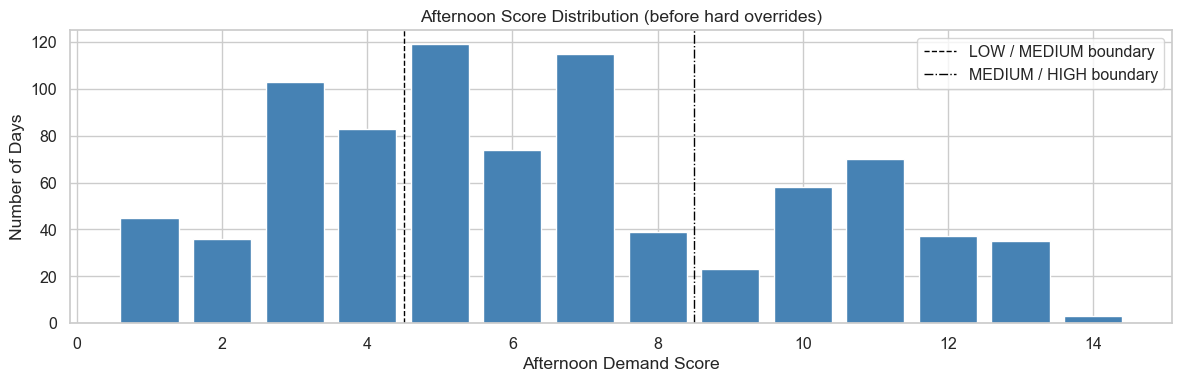

In [4]:
# Score distribution histogram
fig, ax = plt.subplots(figsize=(12, 4))
colors = afternoon["tier"].map({"low": "#4a90d9", "medium": "darkorange", "high": "#d94a4a"})
ax.bar(afternoon["score"].value_counts().sort_index().index,
       afternoon["score"].value_counts().sort_index().values,
       color="steelblue", edgecolor="white")
ax.axvline(4.5  # low/medium boundary at score 4, color="black", ls="--", lw=1, label="LOW / MEDIUM boundary")
ax.axvline(6.5  # medium/high boundary at score 6, color="black", ls="-.", lw=1, label="MEDIUM / HIGH boundary")
ax.set_xlabel("Afternoon Demand Score")
ax.set_ylabel("Number of Days")
ax.set_title("Afternoon Score Distribution (before hard overrides)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Review: Spot Check the Labels

In [5]:
# Combine morning + afternoon
labelled = pd.concat([
    morning[["date", "shift", "tier", "total_headcount"]],
    afternoon[["date", "shift", "tier", "total_headcount"]],
], ignore_index=True).sort_values(["date", "shift"]).reset_index(drop=True)

# Merge back occupancy context for review
review = labelled.merge(occupancy[["date", "occupancy_pct", "day_name", "season",
                              "special_day_name", "temp_mean"]], on="date", how="left")

print("=== Overall tier distribution ===")
print(review.groupby(["shift", "tier"]).size().unstack(fill_value=0))
print()

# Tier by season
print("=== Tier by season (afternoon) ===")
aft_review = review[review["shift"] == "afternoon"]
print(pd.crosstab(aft_review["season"], aft_review["tier"]))
print()

# Tier by season (morning)
print("=== Tier by season (morning) ===")
morn_review = review[review["shift"] == "morning"]
print(pd.crosstab(morn_review["season"], morn_review["tier"]))

=== Overall tier distribution ===
tier       high  low  medium
shift                       
afternoon   385  266     189
morning     332  163     341

=== Tier by season (afternoon) ===
tier    high  low  medium
season                   
Autumn    64   41      63
Spring   114   33      80
Summer   184    0       0
Winter    23  192      46

=== Tier by season (morning) ===
tier    high  low  medium
season                   
Autumn   107    2      59
Spring    51   45     131
Summer   112    2      70
Winter    62  114      81


In [6]:
# Spot check: show some sample rows per tier
for tier in ["low", "medium", "high"]:
    print(f"\n{'='*60}")
    print(f"AFTERNOON — {tier.upper()} tier samples:")
    print("='*60")
    sample = aft_review[aft_review["tier"] == tier].sample(min(8, len(aft_review[aft_review["tier"] == tier])), random_state=42)
    print(sample[["date", "day_name", "season", "occupancy_pct", "temp_mean",
                   "special_day_name", "tier"]].to_string(index=False))


AFTERNOON — LOW tier samples:
='*60
      date day_name season  occupancy_pct  temp_mean special_day_name tier
2025-03-16   Sunday Spring          34.44        6.3              NaN  low
2024-12-02   Monday Winter          66.89        0.3              NaN  low
2025-01-09 Thursday Winter          24.50        8.4              NaN  low
2025-12-21   Sunday Winter          72.19        4.6              NaN  low
2024-01-28   Sunday Winter          12.58        3.2              NaN  low
2026-02-23   Monday Winter          30.46        8.6              NaN  low
2025-01-16 Thursday Winter          51.66       -0.2              NaN  low
2024-11-25   Monday Autumn          44.37        1.8              NaN  low

AFTERNOON — MEDIUM tier samples:
='*60
      date day_name season  occupancy_pct  temp_mean special_day_name   tier
2026-04-02 Thursday Spring          52.32       10.6              NaN medium
2026-03-02   Monday Spring          38.41        7.1              NaN medium
2024-04-05   Frid

## 4. Headcount Targets per Tier

Maps each tier to the correct per-role headcount, as specified by domain expert.

In [7]:
HEADCOUNT_MORNING = {
    "low":    {"leader": 1, "server": 2, "runner": 1, "bartender": 1, "hostess": 1},
    "medium": {"leader": 1, "server": 3, "runner": 2, "bartender": 2, "hostess": 2},
    "high":   {"leader": 2, "server": 4, "runner": 3, "bartender": 3, "hostess": 2},
}

HEADCOUNT_AFTERNOON = {
    "low":    {"leader": 1, "server": 2, "runner": 1, "bartender": 1, "hostess": 1},
    "medium": {"leader": 2, "server": 3, "runner": 3, "bartender": 3, "hostess": 2},
    "high":   {"leader": 4, "server": 5, "runner": 4, "bartender": 4, "hostess": 3},
}

def target_total(shift, tier):
    table = HEADCOUNT_MORNING if shift == "morning" else HEADCOUNT_AFTERNOON
    return sum(table[tier].values())

labelled["target_headcount"] = labelled.apply(
    lambda row: target_total(row["shift"], row["tier"]), axis=1
)

print("Target totals per tier:")
print(f"  Morning:   LOW={target_total('morning','low')}  MED={target_total('morning','medium')}  HIGH={target_total('morning','high')}")
print(f"  Afternoon: LOW={target_total('afternoon','low')}  MED={target_total('afternoon','medium')}  HIGH={target_total('afternoon','high')}")
print()

# Compare actual vs target
labelled["delta"] = labelled["total_headcount"] - labelled["target_headcount"]
print("Actual vs Target headcount (delta):")
print(labelled.groupby(["shift", "tier"])["delta"].describe().round(1))

Target totals per tier:
  Morning:   LOW=6  MED=10  HIGH=14
  Afternoon: LOW=6  MED=13  HIGH=20

Actual vs Target headcount (delta):
                  count  mean  std   min  25%  50%  75%   max
shift     tier                                               
afternoon high    385.0  -5.0  3.7 -13.0 -8.0 -5.0 -3.0  11.0
          low     266.0   7.0  3.6  -4.0  5.0  7.0  9.0  19.0
          medium  189.0   1.1  4.6 -10.0 -3.0  0.0  4.0  18.0
morning   high    332.0  -6.1  2.2 -12.0 -7.0 -6.0 -5.0   7.0
          low     163.0   0.1  2.9  -5.0 -1.0  0.0  1.0  14.0
          medium  341.0  -3.0  2.8  -9.0 -4.0 -3.0 -2.0  21.0


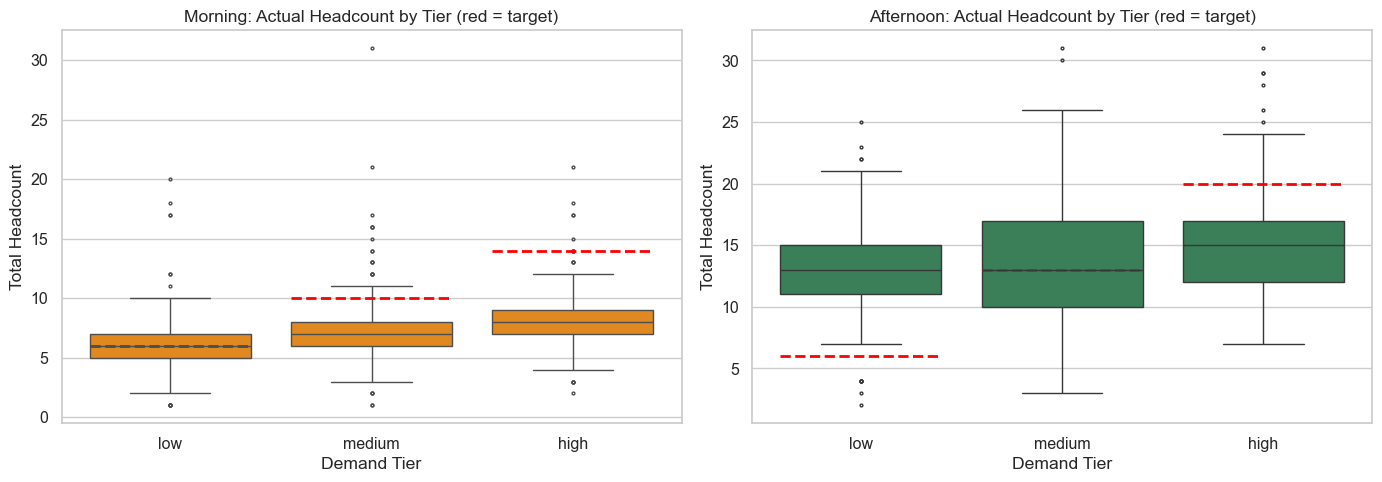

Saved relabel_actual_vs_target.png


In [8]:
# Visualise: actual vs target by tier
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tier_order = ["low", "medium", "high"]

for ax, shift, color in [(axes[0], "morning", "darkorange"), (axes[1], "afternoon", "seagreen")]:
    subset = labelled[labelled["shift"] == shift]
    sns.boxplot(data=subset, x="tier", y="total_headcount", order=tier_order,
                color=color, ax=ax, fliersize=2)
    # Add target lines
    for i, tier in enumerate(tier_order):
        target = target_total(shift, tier)
        ax.hlines(target, i - 0.4, i + 0.4, colors="red", linewidth=2, linestyle="--")
    ax.set_title(f"{shift.title()}: Actual Headcount by Tier (red = target)")
    ax.set_xlabel("Demand Tier")
    ax.set_ylabel("Total Headcount")

plt.tight_layout()
FIG_DIR = Path("../thesis/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "relabel_actual_vs_target.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved relabel_actual_vs_target.png")

## 5. Save Training Data

In [9]:
# Build the final training dataset: features + tier label
training = labelled[["date", "shift", "tier"]].merge(occupancy, on="date", how="left")

out_path = "../data_prep/outputs/training_data.csv"
training.to_csv(out_path, index=False)
print(f"Saved → {out_path}  ({len(training):,} rows)")
print(f"Columns: {list(training.columns)}")
print(f"\nTier distribution:")
print(training.groupby(["shift", "tier"]).size().unstack(fill_value=0))

Saved → ../data_prep/outputs/training_data.csv  (1,676 rows)
Columns: ['date', 'shift', 'tier', 'occupancy_pct', 'day_of_week', 'day_name', 'is_weekend', 'season', 'special_day_name', 'is_special_day', 'temp_max', 'temp_min', 'temp_mean']

Tier distribution:
tier       high  low  medium
shift                       
afternoon   385  266     189
morning     332  163     341
